# Лабораторная работа 2
### Выполнил: Даулетов Максим Александрович

Добро пожаловать в лабораторную работу! 
Оформите ваше решение контеста Kaggle в соответствии с этим шаблоном. Ваша задача - показать проверяющим ход ваших рассуждений, поэтому советуем писать много комментариев к коду и приводить комментарии к логике на каждом этапе в текстовых ячейках. 
Где необходимо, используйте графики для большей наглядности.

При отправке поменяйте название файла на ваши ФИО!

### EDA (исследовательский анализ данных)

В этом разделе вам необходимо провести анализ вашего датасета, интерпретировать признаки, выяснить их значимость и исследовать зависимости между ними.

In [324]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import seaborn as sns
data = pd.read_csv('DOTA2_Train_features.csv', index_col=0)
target = pd.read_csv('DOTA2_Train_targets.csv', index_col=0)
my_seed = 7185 # любое целое число на ваш выбор
random.seed(my_seed)
np.random.seed(my_seed)

In [325]:
data.head()

,game_time,game_mode,lobby_type,objectives_len,chat_len,r1_hero_id,r1_kills,r1_deaths,r1_assists,r1_denies,...,d5_stuns,d5_creeps_stacked,d5_camps_stacked,d5_rune_pickups,d5_firstblood_claimed,d5_teamfight_participation,d5_towers_killed,d5_roshans_killed,d5_obs_placed,d5_sen_placed
match_id,,,,,,,,,,,,,,,,,,,,,
b29797296e310d2275f2cd67eeacf2eb,2117,22,7,15,1,5,4.0,9,15,0,...,0.133,3,1,7,0,0.405,0,0,0,0
49908f2a11d8bc01f6dad6fbf2e39326,3914,22,7,28,177,87,3.0,15,22,5,...,0.000,5,2,14,0,0.352,0,0,1,0
a68557919e4353f6067ddd3a04b980b0,100000000,22,0,6,1,42,0.0,0,1,1,...,17.462,0,0,10,0,0.625,0,0,0,0
f6273df443c5a8b192b633ef2ce34304,475,22,7,1,3,48,0.0,1,0,0,...,0.000,0,0,3,1,0.500,0,0,0,0
71b98e3c7cc8701ad425a69d3923ec8f,581,22,7,1,1,41,0.0,0,0,3,...,0.000,0,0,1,0,0.000,0,0,0,0


Проверим пропуски в данных и сразу их заполним

In [326]:
data.isnull().sum()

game_time                     0
game_mode                     0
lobby_type                    0
objectives_len                0
chat_len                      0
                             ..
d5_teamfight_participation    0
d5_towers_killed              0
d5_roshans_killed             0
d5_obs_placed                 0
d5_sen_placed                 0
Length: 245, dtype: int64

In [327]:
data = data.fillna(data.median())

Добавим целевой признак в текущий датасет, и объединим числовые признаки для каждого игрока в общую статистику команды, для удобства работы с ними.

In [328]:
data = pd.concat([data, target], axis=1)

In [329]:
tps = ['kills','deaths','assists','denies','gold','lh','xp','health','max_health','max_mana','level','x','y','stuns','creeps_stacked','rune_pickups','firstblood_claimed','towers_killed','roshans_killed','obs_placed','sen_placed','camps_stacked']
def summ_feat(data):
    for tp in tps:
        data['r_'+tp] = data['r1_'+tp]+data['r2_'+tp]+data['r3_'+tp]+data['r4_'+tp]+data['r5_'+tp]
        data['d_'+tp] = data['d1_'+tp]+data['d2_'+tp]+data['d3_'+tp]+data['d4_'+tp]+data['d5_'+tp]
        for i in range(1,6):
            data.drop('r'+str(i)+'_'+tp,axis=1,inplace=True)
            data.drop('d'+str(i)+'_'+tp,axis=1,inplace=True)
summ_feat(data)

In [330]:
data.describe()

,game_time,game_mode,lobby_type,objectives_len,chat_len,r1_hero_id,r1_teamfight_participation,r2_hero_id,r2_teamfight_participation,r3_hero_id,...,r_towers_killed,d_towers_killed,r_roshans_killed,d_roshans_killed,r_obs_placed,d_obs_placed,r_sen_placed,d_sen_placed,r_camps_stacked,d_camps_stacked
count,2.777200e+04,27772.000000,27772.000000,27772.000000,27772.000000,27772.000000,27772.000000,27772.000000,27772.000000,27772.000000,...,27772.000000,27772.000000,27772.000000,27772.000000,27772.000000,27772.000000,27772.000000,27772.000000,27772.000000,27772.000000
mean,3.000534e+06,19.587354,4.780678,6.523765,7.427877,51.204523,0.417812,51.386108,0.421668,51.620481,...,1.679785,1.557684,0.146298,0.135568,6.280858,6.207403,3.975299,3.871381,1.314958,1.668335
std,1.705725e+07,6.303789,3.257337,6.507055,13.607843,34.650816,0.268046,34.300916,0.268617,34.317033,...,2.105319,2.089398,0.419133,0.414901,5.063136,5.032949,5.899849,5.812206,1.927348,2.366907
min,0.000000e+00,2.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5.317500e+02,22.000000,0.000000,1.000000,0.000000,20.000000,0.238000,21.000000,0.250000,21.000000,...,0.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000
50%,1.075000e+03,22.000000,7.000000,4.000000,3.000000,44.000000,0.444000,44.000000,0.450000,45.000000,...,1.000000,1.000000,0.000000,0.000000,5.000000,5.000000,2.000000,2.000000,1.000000,1.000000
75%,1.724000e+03,22.000000,7.000000,10.000000,9.000000,81.000000,0.600000,81.000000,0.600000,81.000000,...,3.000000,3.000000,0.000000,0.000000,10.000000,10.000000,5.000000,5.000000,2.000000,2.000000
max,1.000000e+08,23.000000,7.000000,41.000000,291.000000,120.000000,2.000000,120.000000,1.500000,120.000000,...,12.000000,12.000000,5.000000,5.000000,31.000000,29.000000,85.000000,67.000000,18.000000,31.000000


In [331]:
data.groupby('radiant_win').mean()

,game_time,game_mode,lobby_type,objectives_len,chat_len,r1_hero_id,r1_teamfight_participation,r2_hero_id,r2_teamfight_participation,r3_hero_id,...,r_towers_killed,d_towers_killed,r_roshans_killed,d_roshans_killed,r_obs_placed,d_obs_placed,r_sen_placed,d_sen_placed,r_camps_stacked,d_camps_stacked
radiant_win,,,,,,,,,,,,,,,,,,,,,
False,2.989591e+06,19.528488,4.774432,6.713833,7.713531,51.452343,0.414856,51.937590,0.423886,52.060222,...,1.269263,2.075089,0.103237,0.192136,6.333031,6.456041,4.282545,3.885820,1.296657,1.744019
True,3.010520e+06,19.641072,4.786378,6.350320,7.167206,50.978376,0.420510,50.882859,0.419644,51.219200,...,2.054404,1.085531,0.185593,0.083947,6.233248,5.980511,3.694925,3.858205,1.331658,1.599270


Видим, что признаки game_time, game_mode, lobby_type, objectives_len, chat_len имеют малое отличие в значениях для двух исходов, лучше их убрать.



Построим плотности признаков для сравнения в случае победы и поражения для Dire

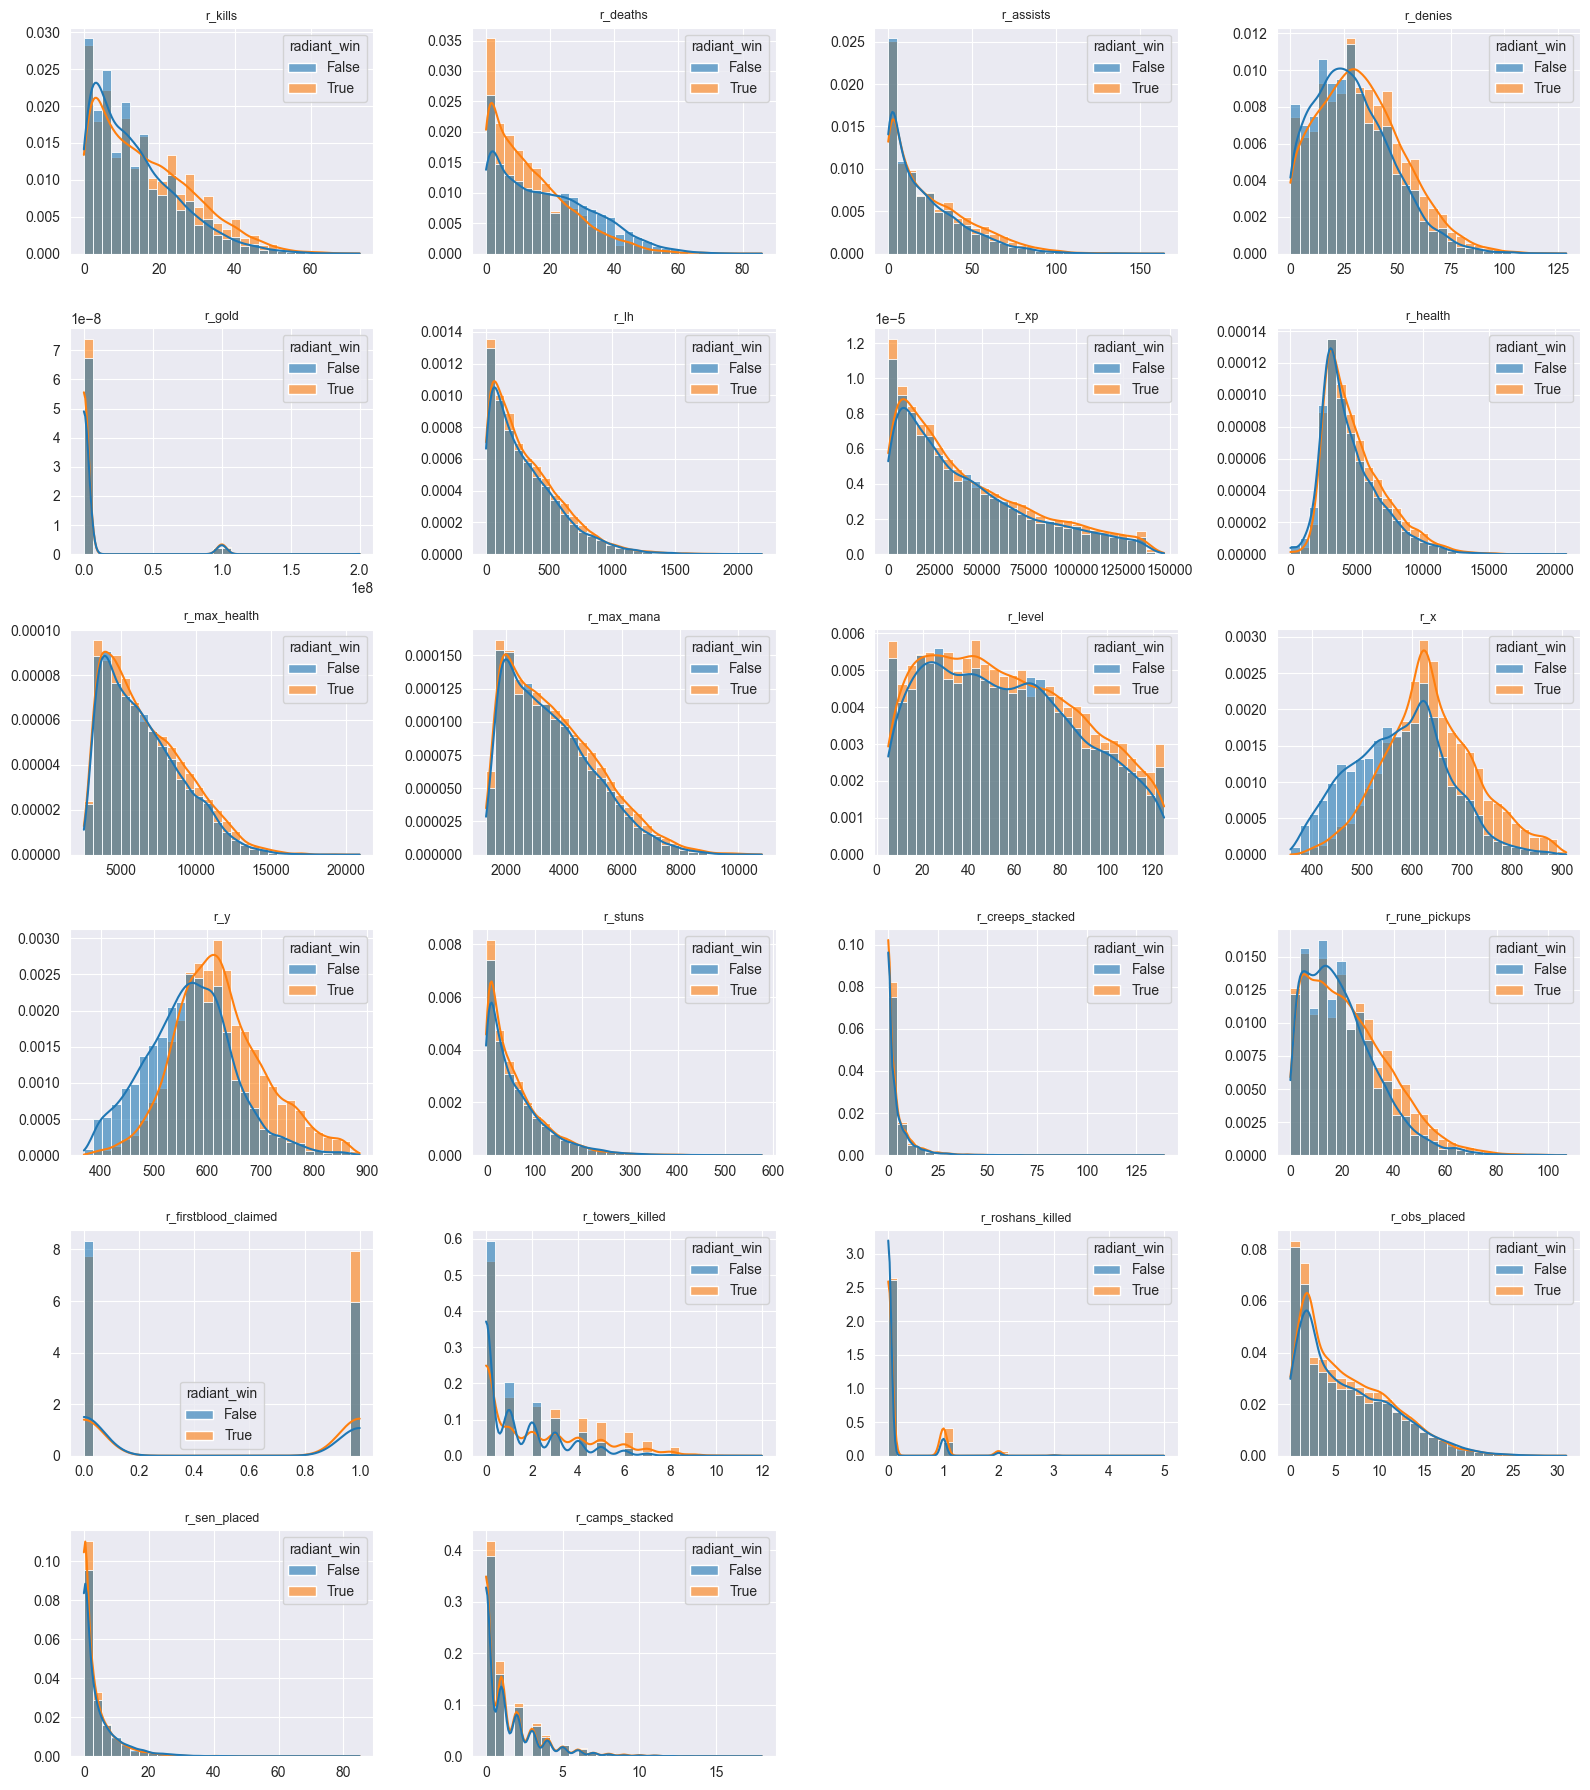

In [332]:
n_cols = 4
n_rows = (len(tps) + n_cols - 1) // n_cols

plt.figure(figsize=(4 * n_cols, 3 * n_rows))

for idx, i in enumerate(tps, 1):
    col_name = f'r_{i}'
    plt.subplot(n_rows, n_cols, idx)
    sns.histplot(data=data, x=col_name, hue='radiant_win', 
         kde=True, alpha=0.6, bins=30,stat='density')
    plt.title(col_name, fontsize=9)
    plt.xlabel('')
    plt.ylabel('')

plt.tight_layout()
plt.show()

Также построим для Radiant

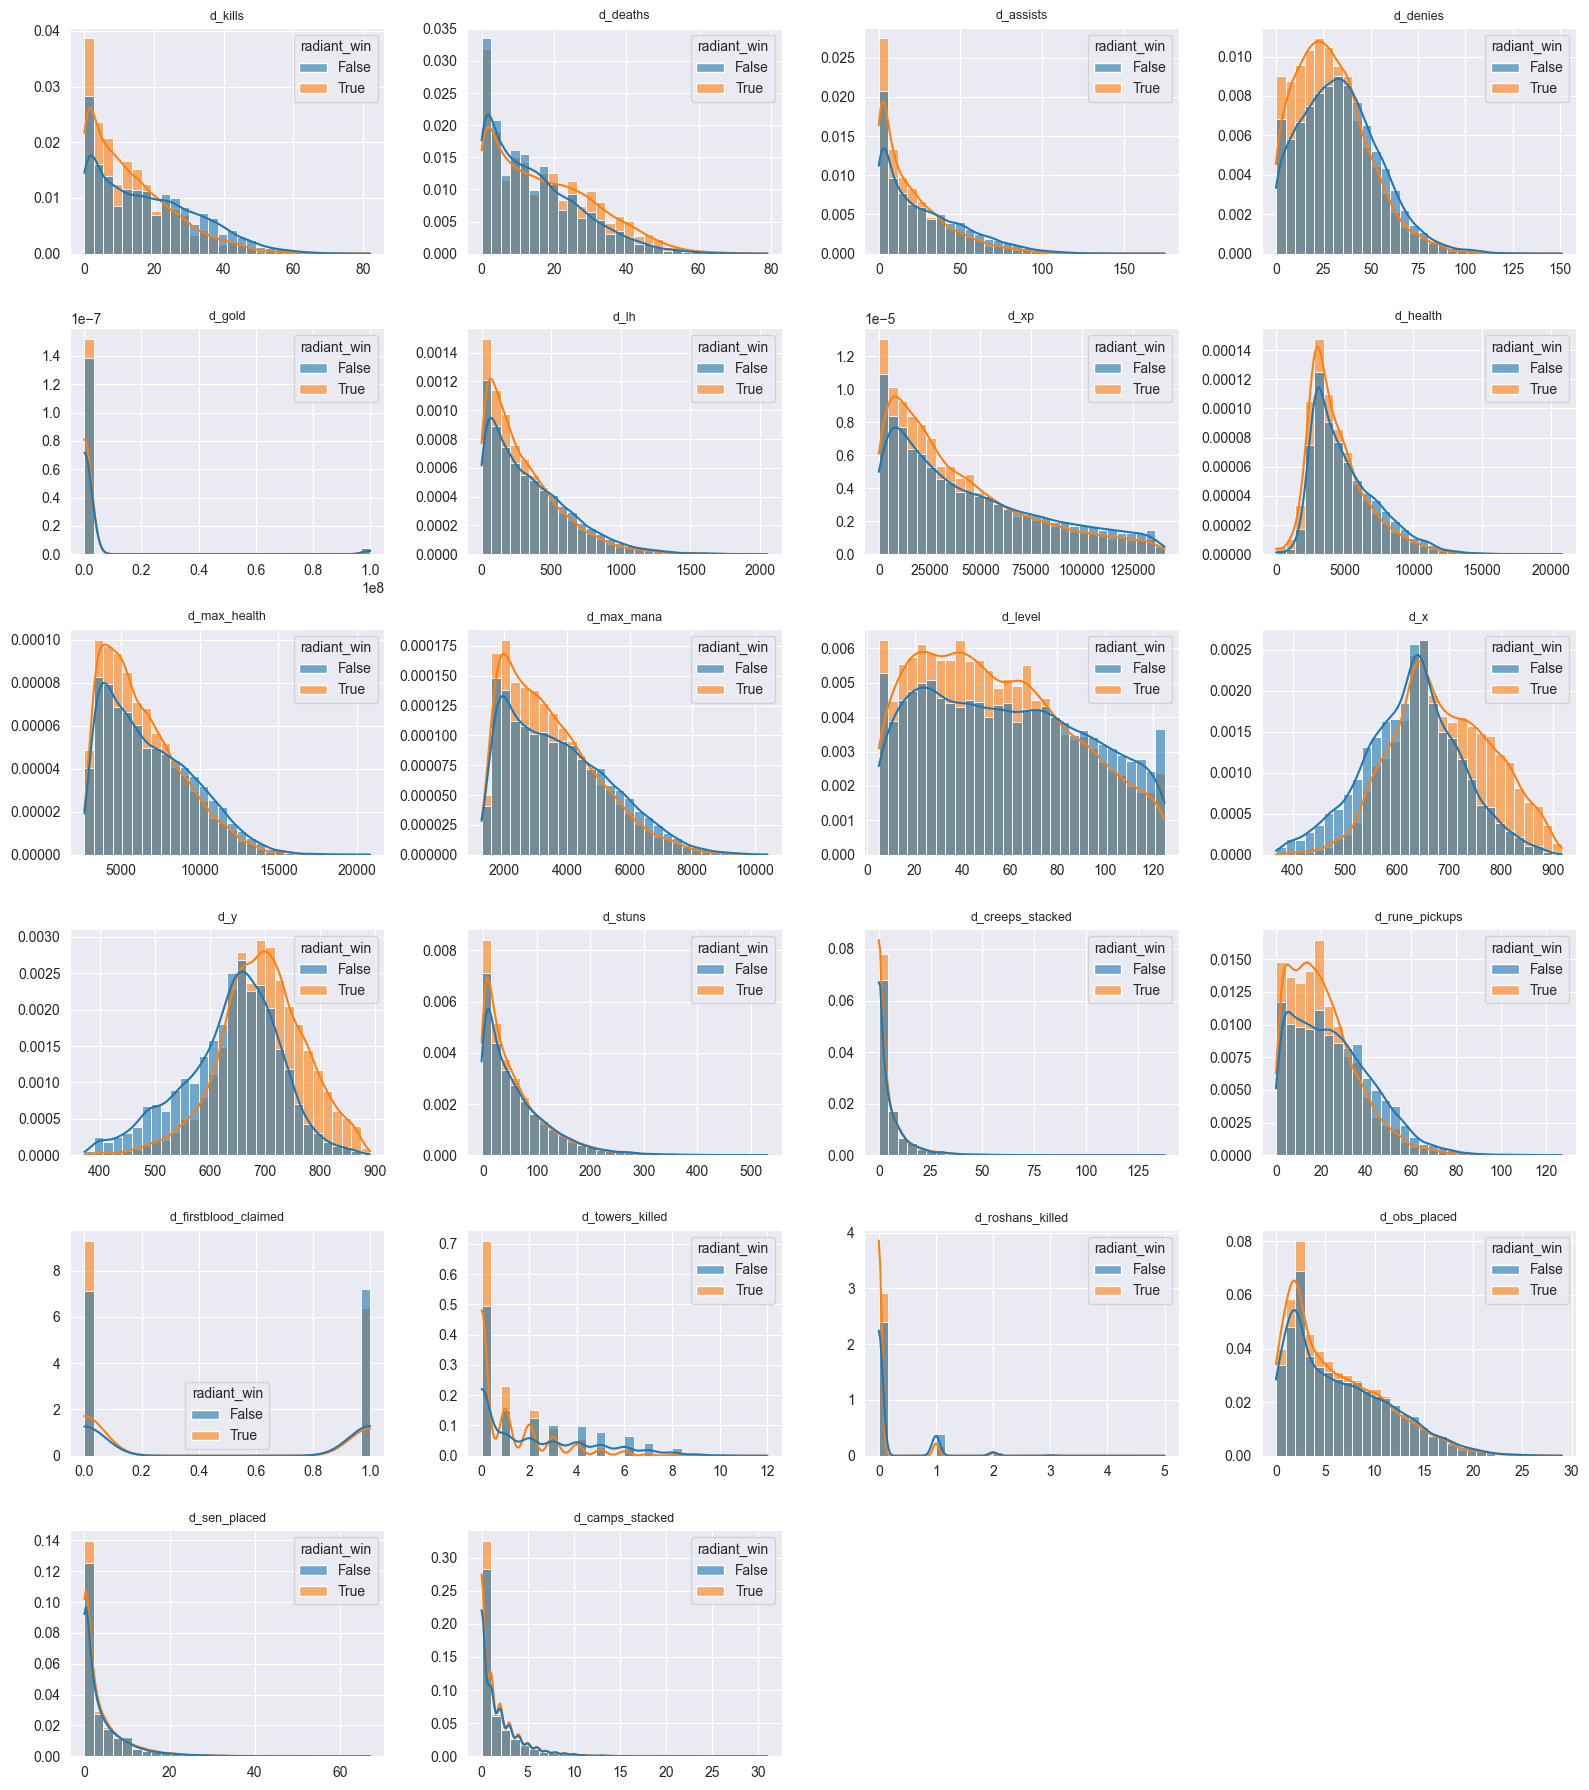

In [333]:
n_cols = 4
n_rows = (len(tps) + n_cols - 1) // n_cols

plt.figure(figsize=(4 * n_cols, 3 * n_rows))

for idx, i in enumerate(tps, 1):
    col_name = f'd_{i}'
    plt.subplot(n_rows, n_cols, idx)
    sns.histplot(data=data, x=col_name, hue='radiant_win', 
         kde=True, alpha=0.6, bins=30,stat='density')
    plt.title(col_name, fontsize=9)
    plt.xlabel('')
    plt.ylabel('')

plt.tight_layout()
plt.show()

Также построим матрицу корреляций между признаками

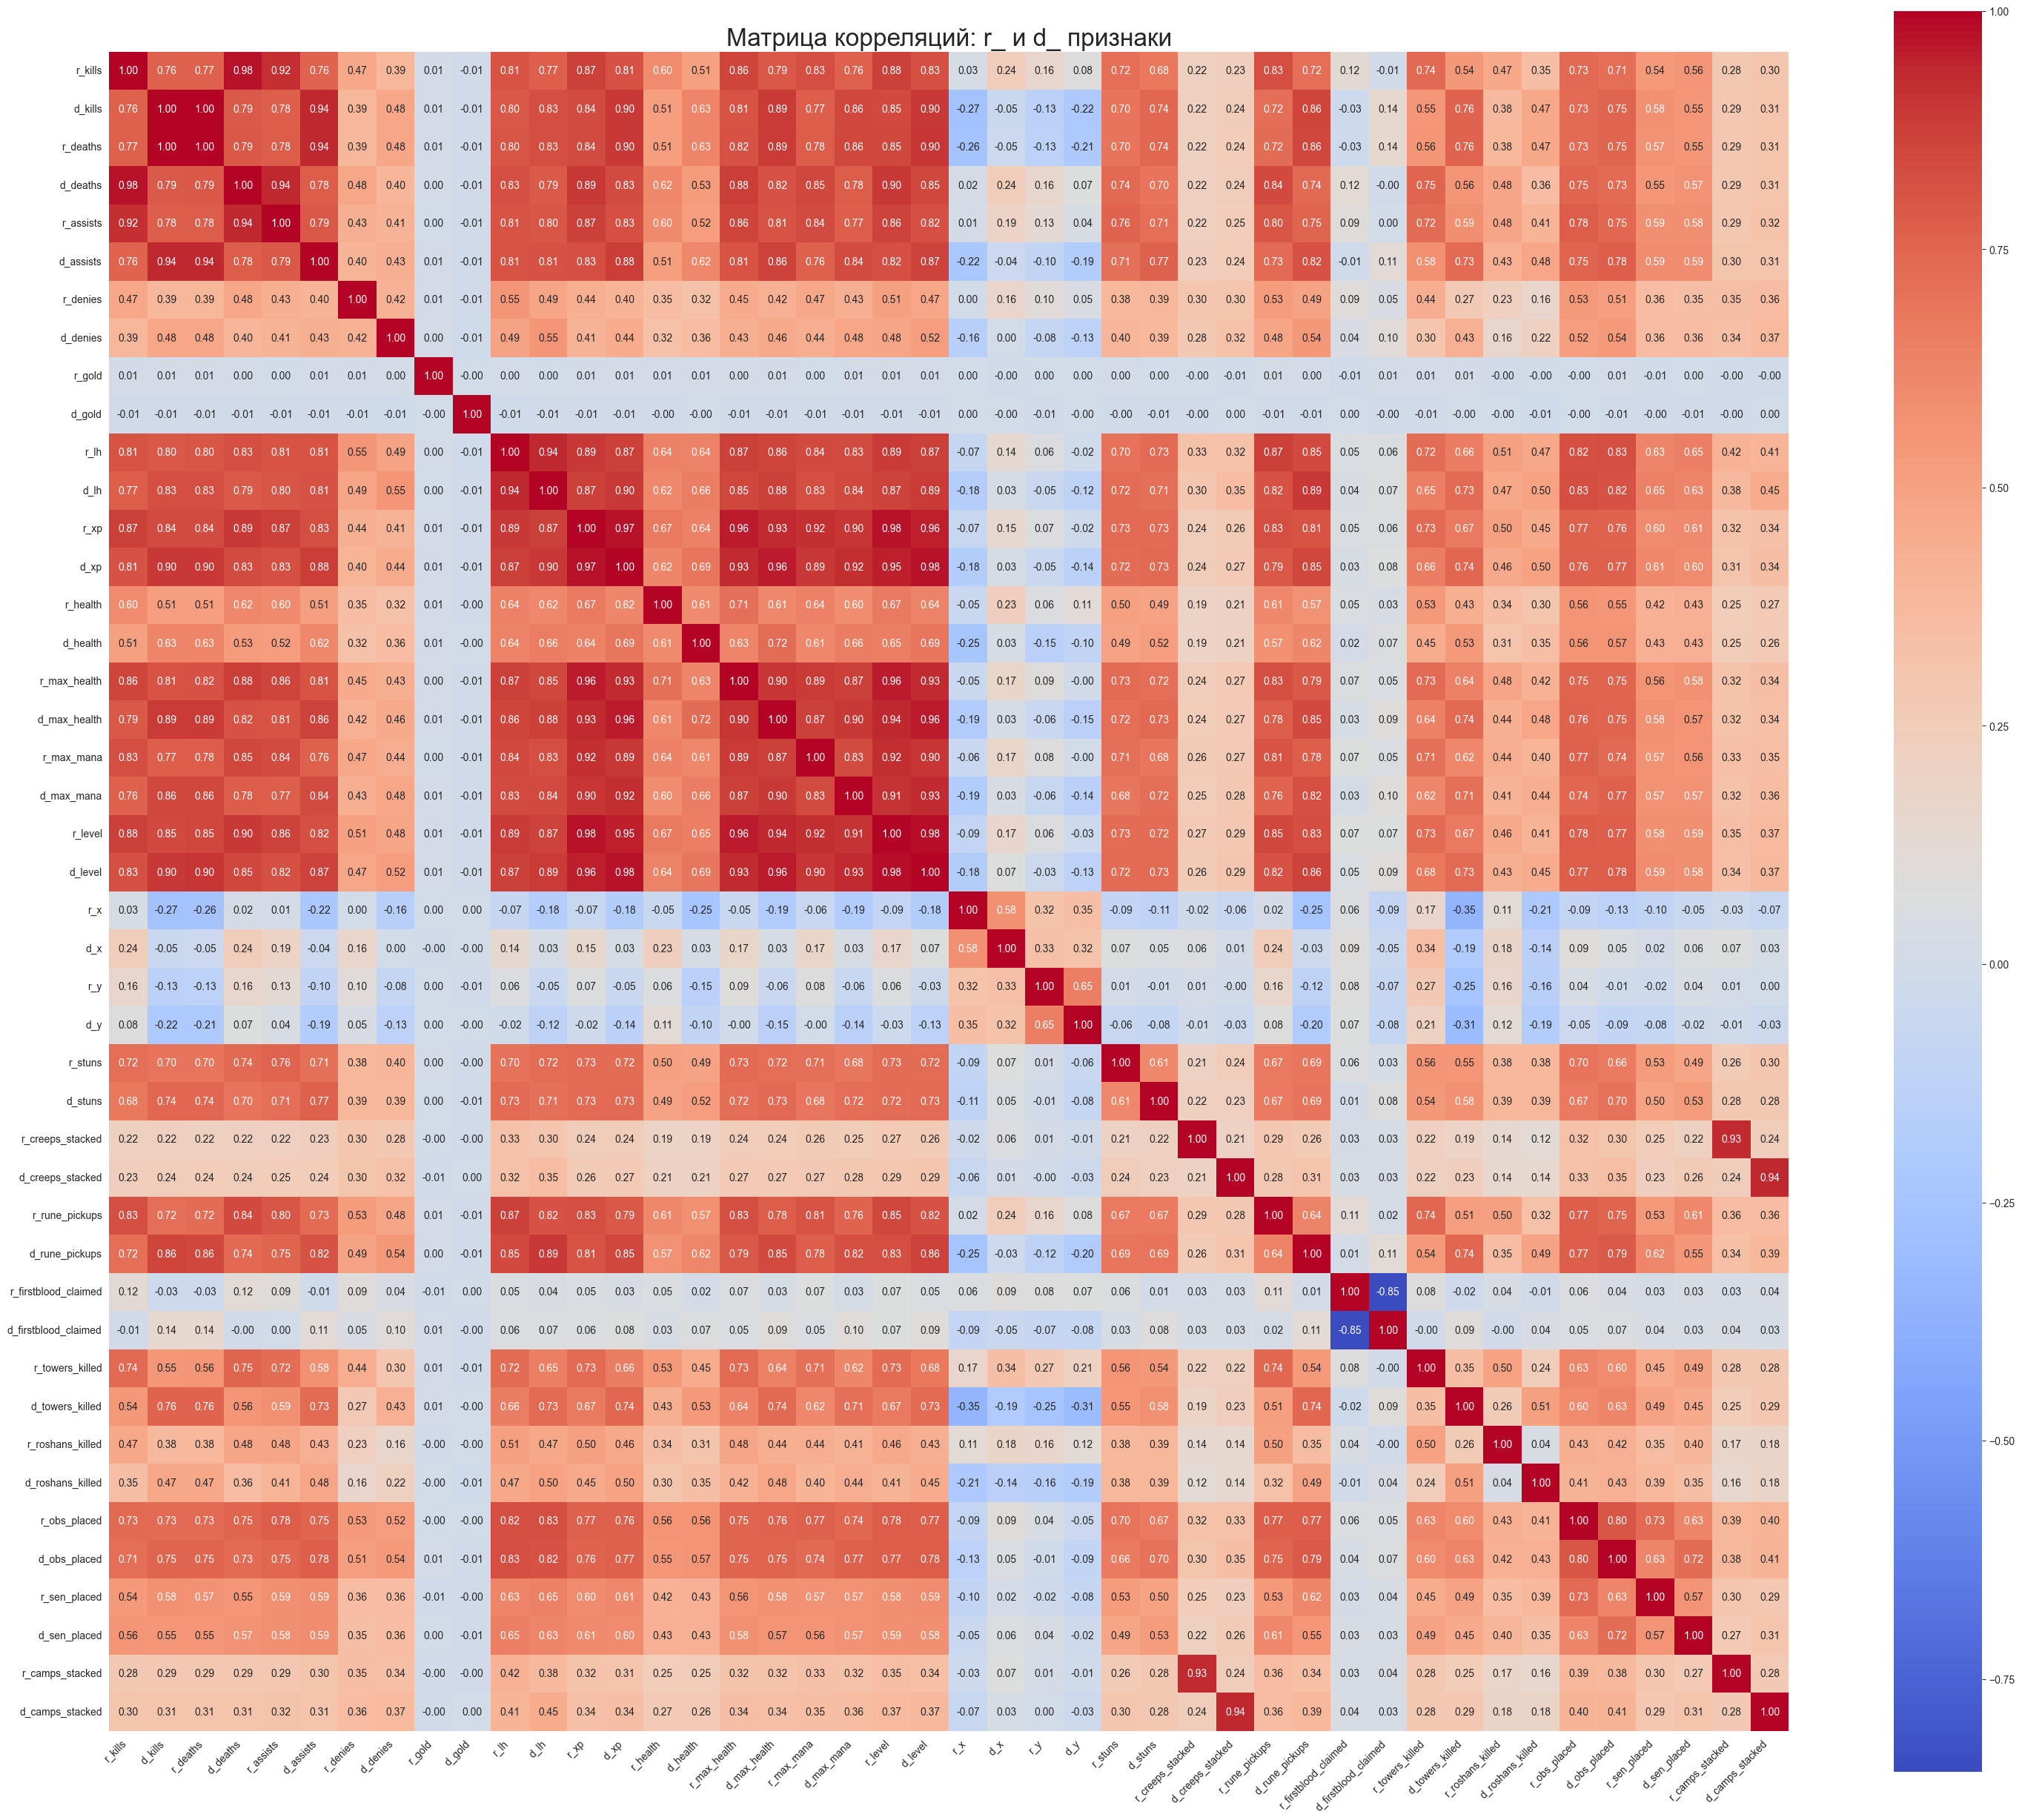

In [334]:
selected_features = []
for feat in tps:
    r_col = f'r_{feat}'
    d_col = f'd_{feat}'
    if r_col in data.columns:
        selected_features.append(r_col)
    if d_col in data.columns:
        selected_features.append(d_col)
data_subset = data[selected_features]
plt.figure(figsize=(30, 30))
correlation_matrix = data_subset.corr()
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    square=True,
    cbar_kws={"shrink": 0.8}
)
plt.title('Матрица корреляций: r_ и d_ признаки', fontsize=24)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Preprocessing (подготовка данных)

 В этом разделе вам необходимо реализовать подготовку ваших данных, в том числе заполнение пропусков, фильтрацию выбросов, кодирование категориальных признаков и т.д. В этот же раздел включите любые операции над данными, которые сочтете нужными.

Сгладим выбросы с помощью замены крайних значений на квантили

In [335]:
from scipy.stats.mstats import winsorize

for col in data.columns:
    data[col] = winsorize(data[col], limits=[0.01, 0.01])

Добавим важные для анализа матча признаки из уже существующих

In [336]:
def add_feat(data):
    #разница золота
    data['gold_diff'] = data['r_gold'] - data['d_gold']
    #разница опыта
    data['xp_diff'] = data['r_xp'] - data['d_xp']
    #КДА
    data['r_kda'] = (data['r_kills'] + data['r_assists']) / (data['r_deaths'] + 1)
    data['d_kda'] = (data['d_kills'] + data['d_assists']) / (data['d_deaths'] + 1)
    data['kda_diff'] = data['r_kda'] - data['d_kda']
    #разница башен
    data['towers_diff'] = data['r_towers_killed'] - data['d_towers_killed']
    #разница убитых рошанов
    data['roshans_diff'] = data['r_roshans_killed'] - data['d_roshans_killed']
    #соотношения золота
    data['r_gold_efficiency'] = data['r_gold'] / (data['r_kills'] + data['r_assists'] + 1)
    data['d_gold_efficiency'] = data['d_gold'] / (data['d_kills'] + data['d_assists'] + 1)
    data['gold_efficiency_diff'] = data['r_gold_efficiency'] - data['d_gold_efficiency']
    #разница крипов
    data['creeps_stacked_diff'] = data['r_creeps_stacked'] - data['d_creeps_stacked']
    #разница вардов
    data['wards_placed_diff'] = (data['r_obs_placed'] + data['r_sen_placed']) - (data['d_obs_placed'] + data['d_sen_placed'])
    #кто получил первый килл
    data['first_blood_advantage'] = (data['r_firstblood_claimed'] > data['d_firstblood_claimed']).astype(int)
    #разница рун
    data['runes_diff'] = data['r_rune_pickups'] - data['d_rune_pickups']
    #средний уровень на команду
    data['r_avg_level'] = (data['r_level']) / 5
    data['d_avg_level'] = (data['d_level']) / 5
    data['level_diff'] = data['r_avg_level'] - data['d_avg_level']
    #комбинация из важных признаков
    data['domination_index'] = (
        0.4 * data['gold_diff'] +
        0.3 * data['xp_diff'] +
        0.2 * data['towers_diff'] +
        0.1 * data['roshans_diff']
    ) / 1000
    #средний процент здоровья
    data['r_health_percent'] = data['r_health'] / (data['r_max_health'] + 1)
    data['d_health_percent'] = data['d_health'] / (data['d_max_health'] + 1)
    data['health_percent_diff'] = data['r_health_percent'] - data['d_health_percent']
    #ластхит на героя
    data['r_lh_per_hero'] = data['r_lh'] / 5
    data['d_lh_per_hero'] = data['d_lh'] / 5
    data['lh_efficiency_diff'] = data['r_lh_per_hero'] - data['d_lh_per_hero']
    #разница денаев
    data['denies_diff'] = data['r_denies'] - data['d_denies']
    #разница станов
    data['stuns_diff'] = data['r_stuns'] - data['d_stuns']
add_feat(data)

Отбросим мало влияющие признаки

In [337]:
ext = ['game_time','game_mode','lobby_type','objectives_len','chat_len']
for i in ext:
    data.drop(i,axis=1,inplace=True)

In [338]:
data.head()

,r1_hero_id,r1_teamfight_participation,r2_hero_id,r2_teamfight_participation,r3_hero_id,r3_teamfight_participation,r4_hero_id,r4_teamfight_participation,r5_hero_id,r5_teamfight_participation,...,level_diff,domination_index,r_health_percent,d_health_percent,health_percent_diff,r_lh_per_hero,d_lh_per_hero,lh_efficiency_diff,denies_diff,stuns_diff
match_id,,,,,,,,,,,,,,,,,,,,,
b29797296e310d2275f2cd67eeacf2eb,5,0.576,17,0.333,59,0.606,26,0.576,12,0.364,...,-1.6,-39991.4921,0.871624,0.999905,-0.128281,113.2,123.8,-10.6,8,195.495
49908f2a11d8bc01f6dad6fbf2e39326,87,0.480,19,0.580,5,0.500,93,0.500,14,0.660,...,0.6,10.6208,0.641760,0.913730,-0.271970,237.4,243.2,-5.8,-20,4.945
a68557919e4353f6067ddd3a04b980b0,42,0.062,18,0.188,7,0.625,9,0.750,17,0.812,...,-0.2,0.0604,0.577649,0.670989,-0.093340,74.8,76.0,-1.2,-33,55.143
f6273df443c5a8b192b633ef2ce34304,48,0.000,32,0.000,14,0.667,19,0.333,11,0.667,...,-0.6,-1.2572,0.520308,0.680117,-0.159809,19.4,29.4,-10.0,-21,9.531
71b98e3c7cc8701ad425a69d3923ec8f,41,0.000,81,0.500,27,0.000,19,0.500,23,0.500,...,0.4,0.7915,0.572722,0.884339,-0.311617,26.0,26.4,-0.4,24,39.957


### Model & training (Выбор модели и её обучение)

В этом разделе описываете модель и ставите эксперименты по обучению.

Если вы ставили много экспериментов, приведите их в хронологическом порядке чтобы мы увидели эволюцию ваших рассуждений.

#### Эксперимент 1

Для начала проверим модель XGB, используем подбор гиперпараметров и кросс-валидацию

In [345]:
from sklearn.model_selection import  StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

scaler = StandardScaler()
X_scaled = scaler.fit_transform(data.drop(columns=['radiant_win']))
y = target['radiant_win']

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

param_distributions = {
    'n_estimators': [500, 1000, 1500],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [4, 6, 8],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9],
    'gamma': [0, 0.1, 0.2],
    'min_child_weight': [1, 3, 5]
}

xgb = XGBClassifier(random_state=42, eval_metric='auc')

random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_distributions,
    n_iter=30,
    scoring='roc_auc',
    cv=cv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_scaled, y)

print("лучшие параметры ", random_search.best_params_)
print("лучший ROC-AUC ", random_search.best_score_)

best_model = random_search.best_estimator_

Fitting 3 folds for each of 30 candidates, totalling 90 fits
лучшие параметры  {'subsample': 0.7, 'n_estimators': 1500, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.01, 'gamma': 0.1, 'colsample_bytree': 0.9}
лучший ROC-AUC  0.8217300985730421


#### Эксперимент 2

Теперь проверим метод ближайших соседей

In [340]:
from sklearn.neighbors import KNeighborsClassifier

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

param_distributions = {
    'n_estimators': [100, 200, 300], 
    'max_depth': [10, 20, None], 
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 0.5]
}

cv_1 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

param_distributions_1 = {
    'n_neighbors': np.arange(5, 101, 5),
    'weights': ['uniform', 'distance'], 
    'metric': ['euclidean', 'manhattan']
}

knn = KNeighborsClassifier(n_jobs=-1) 

random_search = RandomizedSearchCV(
    estimator=knn,
    param_distributions=param_distributions_1,
    n_iter=15,
    scoring='roc_auc',
    cv=cv_1,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_scaled, y)

print("лучшие параметры ", random_search.best_params_)
print("лучший ROC-AUC ", random_search.best_score_)

best_knn_model = random_search.best_estimator_

Fitting 3 folds for each of 15 candidates, totalling 45 fits
лучшие параметры  {'weights': 'uniform', 'n_neighbors': np.int64(80), 'metric': 'manhattan'}
лучший ROC-AUC  0.8019457645014842


#### Эксперимент 3

### Evaluation (оценка качества модели)

В этом разделе проводите оценку качества вашей итоговой модели. 

Выполним предсказание тестового набора, с помощью XGB, так как он дал лучшие результаты при кросс валидации

In [341]:
test_data = pd.read_csv('DOTA2_Test_features.csv', index_col=0)
test_ids = test_data.index
 
test_data = test_data.fillna(test_data.median())

summ_feat(test_data)

for col in test_data.columns:
    test_data[col] = winsorize(test_data[col], limits=[0.01, 0.01])

add_feat(test_data)

for i in ext:
    test_data.drop(i,axis=1,inplace=True)


C:\Users\max_d\AppData\Local\Temp\ipykernel_7900\3221420992.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data['r_'+tp] = data['r1_'+tp]+data['r2_'+tp]+data['r3_'+tp]+data['r4_'+tp]+data['r5_'+tp]
C:\Users\max_d\AppData\Local\Temp\ipykernel_7900\3221420992.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data['d_'+tp] = data['d1_'+tp]+data['d2_'+tp]+data['d3_'+tp]+data['d4_'+tp]+data['d5_'+tp]
C:\Users\max_d\AppData\Local\Temp\ipykernel_7900\3221420992.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is u

In [342]:
test_data.head()

,r1_hero_id,r1_teamfight_participation,r2_hero_id,r2_teamfight_participation,r3_hero_id,r3_teamfight_participation,r4_hero_id,r4_teamfight_participation,r5_hero_id,r5_teamfight_participation,...,level_diff,domination_index,r_health_percent,d_health_percent,health_percent_diff,r_lh_per_hero,d_lh_per_hero,lh_efficiency_diff,denies_diff,stuns_diff
match_id,,,,,,,,,,,,,,,,,,,,,
3071feff2631bd8ca93d0d182e5b9249,95,0.667,91,0.667,73,0.167,92,0.167,32,0.333,...,0.4,0.3552,0.624658,0.689278,-0.064620,24.6,24.4,0.2,-1,-5.168
785b46a41ad7fc643b2fe870e18435e9,2,0.250,105,0.750,39,1.000,119,0.500,9,0.500,...,-1.6,-4.6434,0.925525,0.908424,0.017101,26.2,46.8,-20.6,-46,-5.215
4856a3ccfd84dbd0ab25c0529815978e,18,0.000,14,0.333,74,0.333,41,0.667,20,0.667,...,0.6,0.7424,0.661788,0.724565,-0.062777,17.4,15.2,2.2,-1,17.828
bea45c19efef0f86c03a70280380185d,41,0.444,68,0.389,104,0.389,108,0.167,39,0.722,...,2.6,8.9598,0.940958,0.790130,0.150828,86.4,43.0,43.4,25,18.460
77859b5baddd3a6d0cb05721d9494456,84,0.316,81,0.158,25,0.474,100,0.632,39,0.526,...,1.2,5.6653,0.965072,0.853559,0.111513,54.2,29.6,24.6,4,-59.366


In [343]:
test_data=scaler.transform(test_data)
yy_pred = best_model.predict(test_data)

In [344]:
submission = pd.DataFrame({
    'match_id': test_ids,
    'radiant_win': yy_pred.astype(int)
})

submission.to_csv('submission.csv', index=False)

### Conclusion (Выводы)

В этом разделе описываете полученные результаты и проводите анализ выполненной работы. 
Что получилось / не получилось и почему?

В ходе выполнения лабораторной работы удалось достичь хорошей точности модели, реализовать кросс-валидацию и подбор гиперпараметров. Также удалось добавить новые признаки на основе существующих, что позволило улучшить модель. Не удалось полностью разобрать каждый признак, найти зависимости, объяснить аномалии, из за большого количества самих признаков в датасете. 